In [1]:
import torch

# CUDA Check
print("CUDA available:", torch.cuda.is_available())

CUDA available: True


## Compare model performance between tilt angle (val data), vertical angle (test data)

In [ ]:
from ultralytics import YOLO

# Configuration 
BEST_MODEL_PATH = "../runs/pose/train/weights/best.pt"
DATA_CONFIG = "../config.yaml"

# Load Trained YOLO Pose Model
model = YOLO(BEST_MODEL_PATH)

Ultralytics 8.4.155  Python-3.13.5 torch-2.6.0+cu124 CUDA:0 (Quadro M2200, 4096MiB)
YOLO26s-pose summary (fused): 129 layers, 9,941,157 parameters, 0 gradients, 22.5 GFLOPs
val: Fast image access  (ping: 0.10.0 ms, read: 1991.1343.8 MB/s, size: 892.1 KB)
val: Scanning C:\Users\nada\rat_yolo_pose_estimation\data\labels\val.cache... 527 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 527/527 157.9Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95)     Pose(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 33/33 1.2s/it 40.7s1.2ss
                   all        527        527          1      0.998      0.995      0.716          1      0.998      0.995      0.778
Speed: 6.7ms preprocess, 56.1ms inference, 0.0ms loss, 2.1ms postprocess per image
Results saved to C:\Users\nada\rat_yolo_pose_estimation\runs\pose\val-2
Ultralytics 8.4.155  Python-3.13.5 torch-2.6.0+cu124 CUDA:0 (Quadro M2200, 4096MiB)
YOLO26s-pose summary (fused): 129 laye

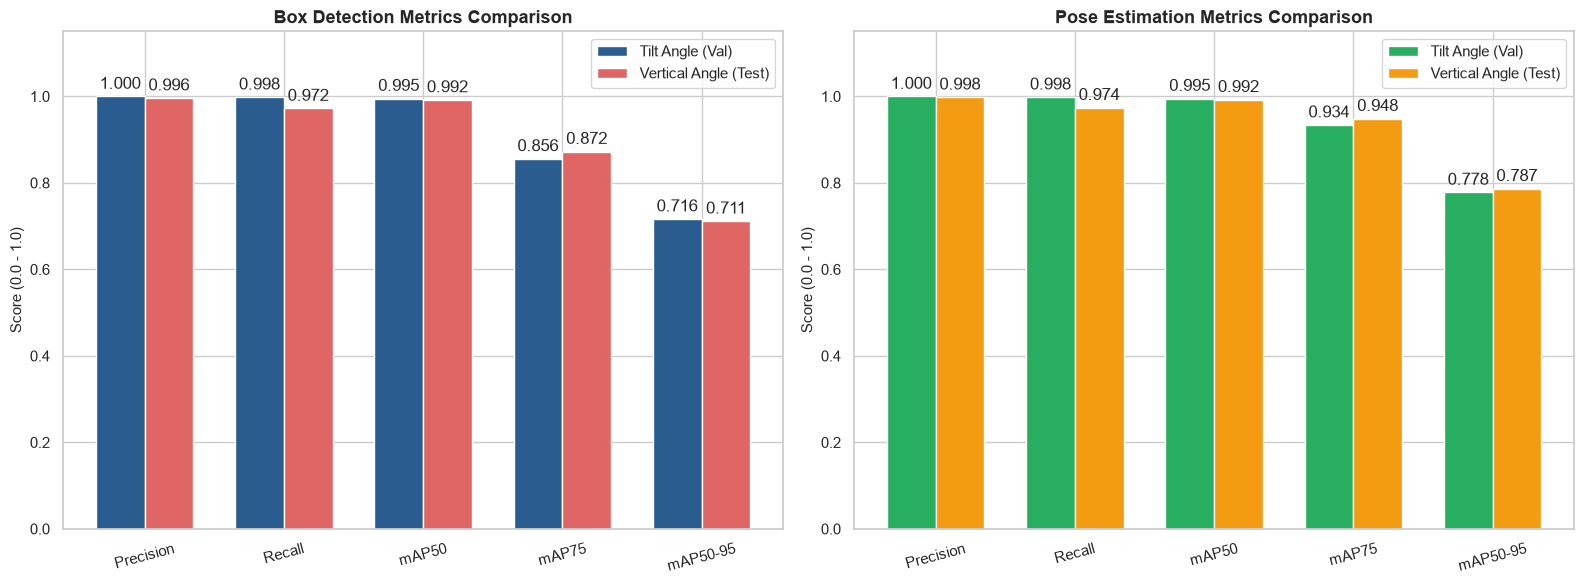

In [8]:
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from ultralytics import YOLO

# Evaluate Validation and Test Sets
tilt_metrics = model.val(data=DATA_CONFIG, split="val")
vertical_metrics = model.val(data=DATA_CONFIG, split="test")

# Collect Evaluation Metrics
metrics = {
    "Metric": [
        "Box Precision",
        "Box Recall",
        "Box mAP50",
        "Box mAP75",
        "Box mAP50-95",
        "Pose Precision",
        "Pose Recall",
        "Pose mAP50",
        "Pose mAP75",
        "Pose mAP50-95",
    ],
    "Tilt Angle (Val)": [
        tilt_metrics.box.mp,
        tilt_metrics.box.mr,
        tilt_metrics.box.map50,
        tilt_metrics.box.map75,
        tilt_metrics.box.map,
        tilt_metrics.pose.mp,
        tilt_metrics.pose.mr,
        tilt_metrics.pose.map50,
        tilt_metrics.pose.map75,
        tilt_metrics.pose.map,
    ],
    "Vertical Angle (Test)": [
        vertical_metrics.box.mp,
        vertical_metrics.box.mr,
        vertical_metrics.box.map50,
        vertical_metrics.box.map75,
        vertical_metrics.box.map,
        vertical_metrics.pose.mp,
        vertical_metrics.pose.mr,
        vertical_metrics.pose.map50,
        vertical_metrics.pose.map75,
        vertical_metrics.pose.map,
    ],
}

df_metrics = pd.DataFrame(metrics)

# Calculate Percentage Change
df_metrics["Change (%)"] = (
    (df_metrics["Vertical Angle (Test)"] - df_metrics["Tilt Angle (Val)"])
    / df_metrics["Tilt Angle (Val)"]
) * 100

# Display Comparison Table
print("\n" + "=" * 80)
print("DETAILED MODEL PERFORMANCE COMPARISON")
print("=" * 80)
print(df_metrics.to_string(index=False, float_format=lambda x: f"{x:.4f}"))

# Configure Plot Style
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(16, 6))
bar_width = 0.35

# Plot Box Detection Metrics
box_df = df_metrics[df_metrics["Metric"].str.startswith("Box")].copy()
x_box = np.arange(len(box_df))

box_tilt = axes[0].bar(
    x_box - bar_width / 2,
    box_df["Tilt Angle (Val)"],
    bar_width,
    label="Tilt Angle (Val)",
    color="#2b5c8f",
)
box_vertical = axes[0].bar(
    x_box + bar_width / 2,
    box_df["Vertical Angle (Test)"],
    bar_width,
    label="Vertical Angle (Test)",
    color="#e06666",
)

axes[0].set_title("Box Detection Metrics Comparison", fontsize=13, fontweight="bold")
axes[0].set_xticks(x_box)
axes[0].set_xticklabels([m.replace("Box ", "") for m in box_df["Metric"]], rotation=15)
axes[0].set_ylabel("Score (0.0 - 1.0)", fontsize=11)
axes[0].set_ylim(0, 1.15)
axes[0].legend()
axes[0].bar_label(box_tilt, fmt="%.3f", padding=3)
axes[0].bar_label(box_vertical, fmt="%.3f", padding=3)

# Plot Pose Estimation Metrics
pose_df = df_metrics[df_metrics["Metric"].str.startswith("Pose")].copy()
x_pose = np.arange(len(pose_df))

pose_tilt = axes[1].bar(
    x_pose - bar_width / 2,
    pose_df["Tilt Angle (Val)"],
    bar_width,
    label="Tilt Angle (Val)",
    color="#27ae60",
)
pose_vertical = axes[1].bar(
    x_pose + bar_width / 2,
    pose_df["Vertical Angle (Test)"],
    bar_width,
    label="Vertical Angle (Test)",
    color="#f39c12",
)

axes[1].set_title("Pose Estimation Metrics Comparison", fontsize=13, fontweight="bold")
axes[1].set_xticks(x_pose)
axes[1].set_xticklabels([m.replace("Pose ", "") for m in pose_df["Metric"]], rotation=15)
axes[1].set_ylabel("Score (0.0 - 1.0)", fontsize=11)
axes[1].set_ylim(0, 1.15)
axes[1].legend()
axes[1].bar_label(pose_tilt, fmt="%.3f", padding=3)
axes[1].bar_label(pose_vertical, fmt="%.3f", padding=3)

plt.tight_layout()
plt.show()

# Per-Keypoint (PCK @0.05, @0.1 and @0.2 )

Number of keypoints: 10
Keypoints: ['Right Hindlimb', 'Left Hindlimb', 'Right Forelimb', 'Left Forelimb', 'Tail Root', 'Head', 'Neck', 'Spine Midpoint', 'Tail Midpoint', 'Tail Endpoint']

Calculating Tilt Angle (Val) PCK for @0.05, @0.10 and @0.20...
Calculating Vertical Angle (Test) PCK for @0.05, @0.10 and @0.20...

PER-KEYPOINT PCK@0.05 COMPARISON
      Keypoint  Tilt Angle (Val)  Vertical Angle (Test)
Right Hindlimb            0.6130                 0.5099
 Left Hindlimb            0.6692                 0.6277
Right Forelimb            0.6874                 0.7115
 Left Forelimb            0.6440                 0.6640
     Tail Root            0.8954                 0.9664
          Head            0.9006                 0.8730
          Neck            0.6768                 0.7451
Spine Midpoint            0.8626                 0.8436
 Tail Midpoint            0.6407                 0.6508
 Tail Endpoint            0.8688                 0.8688

PER-KEYPOINT PCK@0.10 COMPARIS

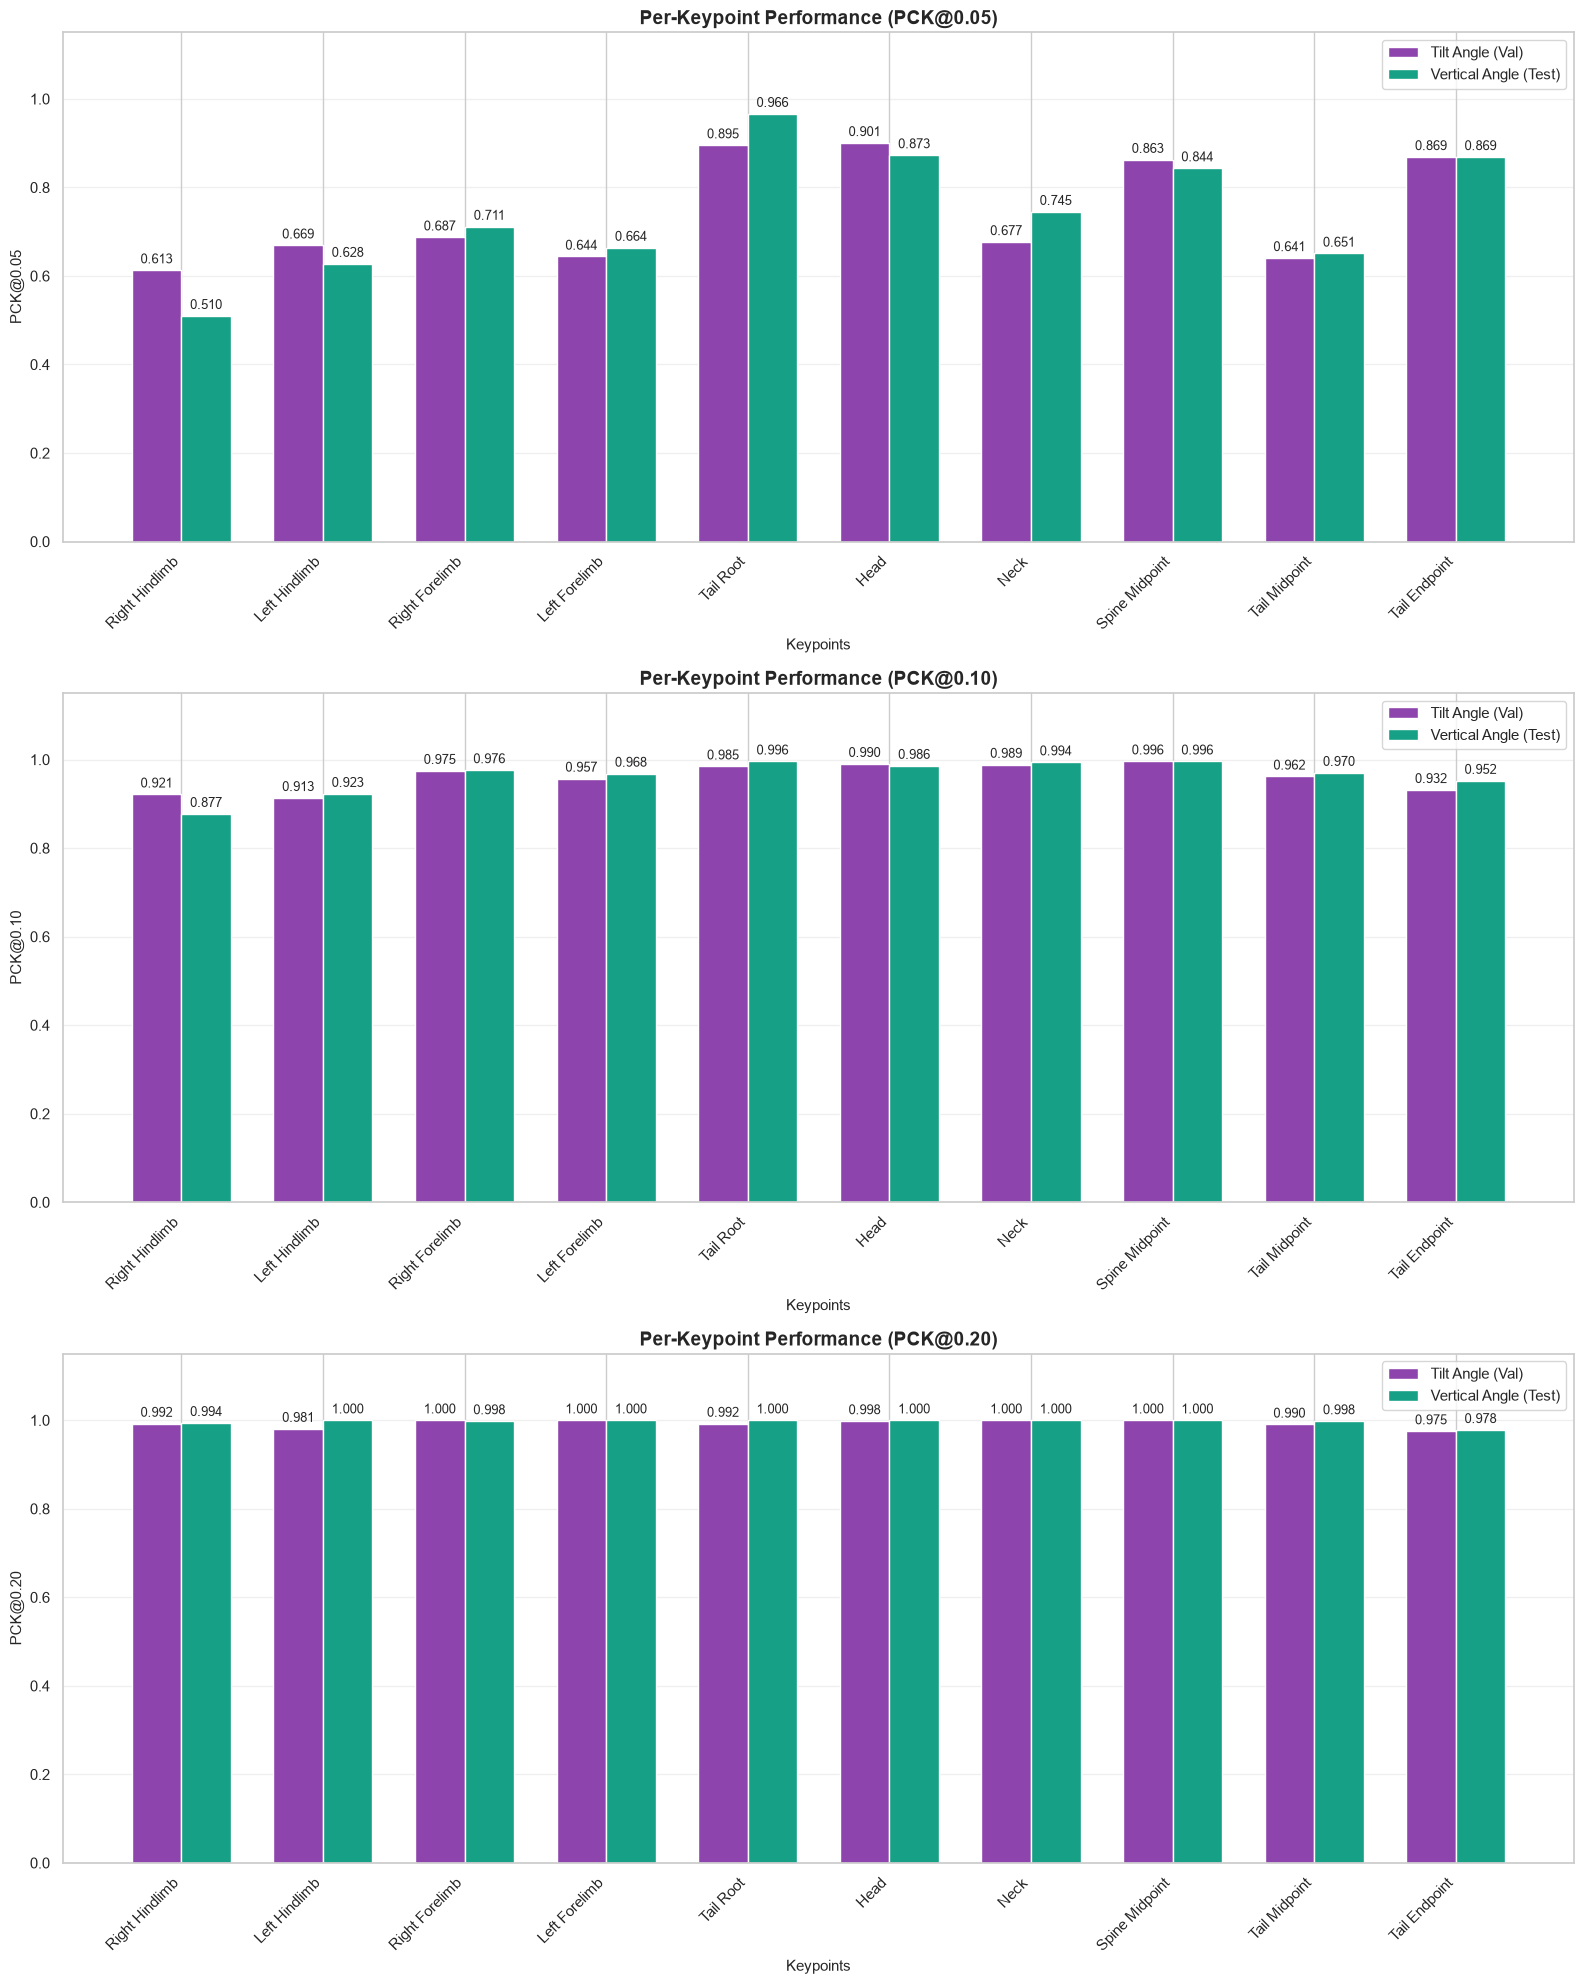

In [3]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import yaml


# Read configuration
with open(DATA_CONFIG, "r", encoding="utf-8") as file:
    config_data = yaml.safe_load(file)

kpt_names = config_data["kpt_names"]

print(f"Number of keypoints: {len(kpt_names)}")
print(f"Keypoints: {kpt_names}")


# Dataset paths
dataset_root = Path(config_data.get("path", "."))

val_images = dataset_root / config_data["val"]
test_images = dataset_root / config_data["test"]

val_labels = Path(str(val_images).replace("images", "labels"))
test_labels = Path(str(test_images).replace("images", "labels"))


# PCK calculation
def calculate_pck_multi_thresholds(image_dir, label_dir, thresholds=(0.05, 0.10, 0.20)):

    num_keypoints = len(kpt_names)

    correct = {
        threshold: np.zeros(num_keypoints, dtype=int)
        for threshold in thresholds
    }

    total = np.zeros(num_keypoints, dtype=int)

    # Get images
    image_files = []

    for extension in ("*.jpg", "*.jpeg", "*.png", "*.bmp", "*.webp"):
        image_files.extend(Path(image_dir).glob(extension))

    image_files = sorted(image_files)

    # Process images
    for image_path in image_files:

        label_path = Path(label_dir) / f"{image_path.stem}.txt"

        if not label_path.exists():
            continue

        # YOLO Pose prediction
        results = model.predict(source=str(image_path), verbose=False)

        if not results:
            continue

        result = results[0]

        if result.keypoints is None:
            continue

        if len(result.keypoints.xy) == 0:
            continue

        predicted_keypoints = result.keypoints.xy.cpu().numpy()
        image_height, image_width = result.orig_shape

        # Ground-truth labels
        try:
            labels = np.loadtxt(label_path, ndmin=2)
        except Exception:
            continue

        if labels.size == 0:
            continue

        # Process each ground-truth object
        for gt in labels:

            x_center = gt[1]
            y_center = gt[2]
            bbox_width = gt[3]
            bbox_height = gt[4]
            gt_keypoints = gt[5:]

            if len(gt_keypoints) != num_keypoints * 3:
                continue

            gt_keypoints = gt_keypoints.reshape(num_keypoints, 3)

            gt_x = gt_keypoints[:, 0]
            gt_y = gt_keypoints[:, 1]
            visibility = gt_keypoints[:, 2]

            # Convert normalized coordinates to pixels
            gt_points = np.column_stack((
                gt_x * image_width,
                gt_y * image_height
            ))

            # Select prediction closest to GT center
            if len(predicted_keypoints) == 1:
                predicted_points = predicted_keypoints[0]

            else:
                predicted_centers = predicted_keypoints.mean(axis=1)

                gt_center = np.array([
                    x_center * image_width,
                    y_center * image_height
                ])

                distances = np.linalg.norm(predicted_centers - gt_center, axis=1)
                best_prediction = np.argmin(distances)

                predicted_points = predicted_keypoints[best_prediction]

            # Normalize error by bounding-box diagonal
            bbox_width_pixels = bbox_width * image_width
            bbox_height_pixels = bbox_height * image_height

            bbox_diagonal = np.sqrt(
                bbox_width_pixels ** 2 +
                bbox_height_pixels ** 2
            )

            if bbox_diagonal <= 0:
                continue

            # Calculate normalized keypoint errors
            errors = np.linalg.norm(predicted_points - gt_points, axis=1)
            normalized_errors = errors / bbox_diagonal

            # Calculate PCK
            for kp_idx in range(num_keypoints):

                if visibility[kp_idx] <= 0:
                    continue

                total[kp_idx] += 1

                for threshold in thresholds:

                    if normalized_errors[kp_idx] <= threshold:
                        correct[threshold][kp_idx] += 1

    # Final PCK values
    pck_results = {}

    for threshold in thresholds:

        pck_results[threshold] = np.divide(
            correct[threshold],
            total,
            out=np.zeros(num_keypoints),
            where=total != 0
        )

    return pck_results, total


# Calculate PCK
print("\nCalculating Tilt Angle (Val) PCK for @0.05, @0.10 and @0.20...")

tilt_pck_dict, tilt_total = calculate_pck_multi_thresholds(
    val_images, val_labels, thresholds=(0.05, 0.10, 0.20)
)

print("Calculating Vertical Angle (Test) PCK for @0.05, @0.10 and @0.20...")

vertical_pck_dict, vertical_total = calculate_pck_multi_thresholds(
    test_images, test_labels, thresholds=(0.05, 0.10, 0.20)
)


# Build result tables
df_pck = {}

for threshold in (0.05, 0.10, 0.20):

    df_pck[threshold] = pd.DataFrame({
        "Keypoint": kpt_names,
        "Tilt Angle (Val)": tilt_pck_dict[threshold],
        "Vertical Angle (Test)": vertical_pck_dict[threshold]
    })


# Print per-keypoint PCK
for threshold in (0.05, 0.10, 0.20):

    print("\n" + "=" * 80)
    print(f"PER-KEYPOINT PCK@{threshold:.2f} COMPARISON")
    print("=" * 80)

    print(df_pck[threshold].to_string(
        index=False,
        float_format=lambda x: f"{x:.4f}"
    ))


# Overall PCK
print("\n" + "=" * 80)
print("OVERALL PCK")
print("=" * 80)

for threshold in (0.05, 0.10, 0.20):

    tilt_correct = (tilt_pck_dict[threshold] * tilt_total).sum()
    vertical_correct = (vertical_pck_dict[threshold] * vertical_total).sum()

    tilt_overall = (
        tilt_correct / tilt_total.sum()
        if tilt_total.sum() > 0
        else 0
    )

    vertical_overall = (
        vertical_correct / vertical_total.sum()
        if vertical_total.sum() > 0
        else 0
    )

    print(
        f"PCK@{threshold:.2f} | "
        f"Tilt Angle (Val) = {tilt_overall:.4f} | "
        f"Vertical Angle (Test) = {vertical_overall:.4f}"
    )


# Visualization
sns.set_theme(style="whitegrid")

fig, axes = plt.subplots(3, 1, figsize=(16, 20))

x = np.arange(len(kpt_names))
bar_width = 0.35

for ax, threshold in zip(axes, (0.05, 0.10, 0.20)):

    df = df_pck[threshold]

    bars_tilt = ax.bar(
        x - bar_width / 2,
        df["Tilt Angle (Val)"],
        bar_width,
        label="Tilt Angle (Val)",
        color="#8e44ad"
    )

    bars_vertical = ax.bar(
        x + bar_width / 2,
        df["Vertical Angle (Test)"],
        bar_width,
        label="Vertical Angle (Test)",
        color="#16a085"
    )

    ax.set_title(f"Per-Keypoint Performance (PCK@{threshold:.2f})", fontsize=14, fontweight="bold")
    ax.set_xlabel("Keypoints", fontsize=11)
    ax.set_ylabel(f"PCK@{threshold:.2f}", fontsize=11)

    ax.set_xticks(x)
    ax.set_xticklabels(kpt_names, rotation=45, ha="right")
    ax.set_ylim(0, 1.15)

    ax.legend(loc="upper right")

    ax.bar_label(bars_tilt, fmt="%.3f", padding=3, fontsize=9)
    ax.bar_label(bars_vertical, fmt="%.3f", padding=3, fontsize=9)

    ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

# Comparative Evaluation: Tilt vs. Vertical Viewpoints

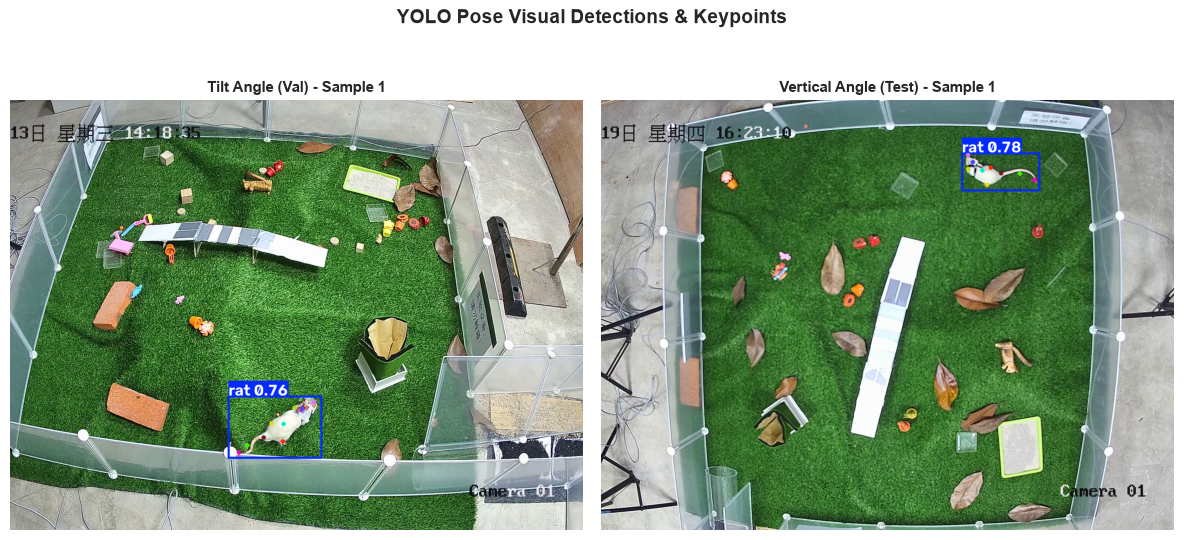

In [5]:
from pathlib import Path
import cv2
import matplotlib.pyplot as plt
import yaml
from ultralytics import YOLO

NUM_SAMPLES = 1

def visualize_samples_auto(model_instance, yaml_path, num_samples=1):
    with open(yaml_path, "r") as f:
        config_data = yaml.safe_load(f)

    dataset_root = Path(config_data.get("path", ""))

    fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(12, 6))

    splits = ["val", "test"]
    split_titles = ["Tilt Angle (Val)", "Vertical Angle (Test)"]

    for idx, split in enumerate(splits):
        img_dir = dataset_root / config_data[split]
        img_paths = sorted(
            list(img_dir.glob("*.jpg")) + list(img_dir.glob("*.png"))
        )[:num_samples]

        for col_idx, img_path in enumerate(img_paths):
            ax = axes[idx]

            # Run Inference
            results = model_instance.predict(
                source=str(img_path), save=False, verbose=False
            )
            res = results[0]

            # Render Overlay
            rendered_bgr = res.plot(boxes=True, kpt_radius=5, kpt_line=True)
            rendered_rgb = cv2.cvtColor(rendered_bgr, cv2.COLOR_BGR2RGB)

            ax.imshow(rendered_rgb)
            ax.set_title(
                f"{split_titles[idx]} - Sample {col_idx + 1}",
                fontsize=11,
                fontweight="bold",
            )
            ax.axis("off")

    plt.suptitle(
        "YOLO Pose Visual Detections & Keypoints",
        fontsize=14,
        fontweight="bold",
        y=0.98,
    )
    plt.tight_layout()
    plt.show()


# Execution
visualize_samples_auto(
    model_instance=model,
    yaml_path=DATA_CONFIG,
    num_samples=NUM_SAMPLES,
)

# Inference Speed & Latency Evaluation

In [9]:
import pandas as pd

speed_data = {
    "Stage": ["Pre-process", "Inference", "Post-process", "Total Time per Image"],
    "Tilt Angle (ms)": [
        tilt_metrics.speed["preprocess"],
        tilt_metrics.speed["inference"],
        tilt_metrics.speed["postprocess"],
        sum(tilt_metrics.speed.values()),
    ],
    "Vertical Angle (ms)": [
        vertical_metrics.speed["preprocess"],
        vertical_metrics.speed["inference"],
        vertical_metrics.speed["postprocess"],
        sum(vertical_metrics.speed.values()),
    ],
}

df_speed = pd.DataFrame(speed_data)
print("\n Latency and Speed Comparison (ms) ")
print(df_speed.to_string(index=False))


 Latency and Speed Comparison (ms) 
               Stage  Tilt Angle (ms)  Vertical Angle (ms)
         Pre-process         6.676880             5.257114
           Inference        56.101331            55.910782
        Post-process         2.121137             1.738855
Total Time per Image        64.900539            62.907955


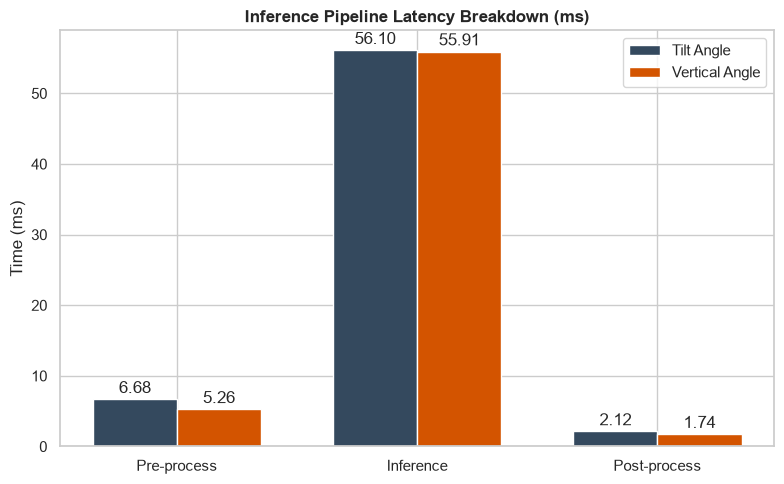

In [10]:
# Visualization
sns.set_theme(style="whitegrid")
plt.figure(figsize=(8, 5))
stages = ["preprocess", "inference", "postprocess"]
x_stages = np.arange(len(stages))
width = 0.35

r1 = plt.bar(
    x_stages - width / 2,
    [tilt_metrics.speed[s] for s in stages],
    width,
    label="Tilt Angle",
    color="#34495e",
)
r2 = plt.bar(
    x_stages + width / 2,
    [vertical_metrics.speed[s] for s in stages],
    width,
    label="Vertical Angle",
    color="#d35400",
)

plt.title(
    "Inference Pipeline Latency Breakdown (ms)", fontsize=12, fontweight="bold"
)
plt.xticks(x_stages, ["Pre-process", "Inference", "Post-process"])
plt.ylabel("Time (ms)")
plt.legend()
plt.bar_label(r1, fmt="%.2f", padding=2)
plt.bar_label(r2, fmt="%.2f", padding=2)
plt.tight_layout()
plt.show()